In [2]:
# Identificación de Z1 y Z2, montando la señal MC Higgs, MC ZZ y los datos Run2012B, para el canal 4l
# ademas de aplixar delta R, Parámetro impacto dxy<0.5, dz<1.0 y una luminosidad de 4.4669 fb inversos

In [3]:
import uproot
import awkward as ak
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import mplhep as hep

In [4]:

file = uproot.open("C:/Users/HP/Documents/Practica Profesional/Analisis BosonHiggs/Data Sets/Run2012B_DoubleMuParked.root")
tree = file['Events']

# Listar ramas (variables físicas)

print(tree.keys())
tree.keys()
print (['nMuon', 'Muon_pt', 'Muon_eta', 'Muon_phi', 'Muon_mass', 'Muon_charge','Muon_pfRelIso04_all', 'Muon_dxy', 'Muon_dz', 'Muon_dxyErr', 'Muon_dzErr'])

# Archivos de simulación Monte Carlo 
# Señal: H → ZZ* → 4μ
file_higgs = uproot.open("C:/Users/HP/Documents/Practica Profesional/Analisis BosonHiggs/Data Sets/SMHiggsToZZTo4L.root")
tree_higgs = file_higgs['Events']

# Fondo: ZZ → 4μ
file_zz = uproot.open("C:/Users/HP/Documents/Practica Profesional/Analisis BosonHiggs/Data Sets/ZZTo4mu.root")
tree_zz = file_zz['Events']



['run', 'luminosityBlock', 'event', 'PV_npvs', 'PV_x', 'PV_y', 'PV_z', 'nMuon', 'Muon_pt', 'Muon_eta', 'Muon_phi', 'Muon_mass', 'Muon_charge', 'Muon_pfRelIso03_all', 'Muon_pfRelIso04_all', 'Muon_dxy', 'Muon_dxyErr', 'Muon_dz', 'Muon_dzErr', 'nElectron', 'Electron_pt', 'Electron_eta', 'Electron_phi', 'Electron_mass', 'Electron_charge', 'Electron_pfRelIso03_all', 'Electron_dxy', 'Electron_dxyErr', 'Electron_dz', 'Electron_dzErr', 'MET_pt', 'MET_phi']
['nMuon', 'Muon_pt', 'Muon_eta', 'Muon_phi', 'Muon_mass', 'Muon_charge', 'Muon_pfRelIso04_all', 'Muon_dxy', 'Muon_dz', 'Muon_dxyErr', 'Muon_dzErr']


In [5]:
# Extraer variables físicas de los tres archivos a dataframes 
ramas = ['Muon_pt', 'Muon_eta', 'Muon_phi', 'Muon_charge', 'Muon_pfRelIso04_all', 'Muon_dxy', 'Muon_dz', 'Muon_dxyErr', 'Muon_dzErr']

# Datos reales (Run2012B)
df_data = tree.arrays(ramas, library="ak")

# Simulación Higgs MC
df_higgs = tree_higgs.arrays(ramas, library="ak")

# Simulación fondo ZZ MC
df_zz = tree_zz.arrays(ramas, library="ak")

print("Entradas totales en el archivo de datos:", tree.num_entries)
print("Entradas totales en el archivo de Higgs:", tree_higgs.num_entries)
print("Entradas totales en el archivo de ZZ:", tree_zz.num_entries)

Entradas totales en el archivo de datos: 26084708
Entradas totales en el archivo de Higgs: 299973
Entradas totales en el archivo de ZZ: 1499064


In [6]:
# Dividimos las listas en columnas individuales para 4 muones

mask = ak.num(df_data["Muon_pt"]) >= 4
filtered = df_data[mask]  # Awkward array filtrado

# Creamos el DataFrame de Pandas extrayendo los valores directamente 
df_4mu = pd.DataFrame({ # Muón 1
        "pt1": ak.to_numpy(filtered["Muon_pt"][:, 0]),
        "eta1": ak.to_numpy(filtered["Muon_eta"][:, 0]),
        "phi1": ak.to_numpy(filtered["Muon_phi"][:, 0]),
        "charge1": ak.to_numpy(filtered["Muon_charge"][:, 0]),
        "iso1": ak.to_numpy(filtered["Muon_pfRelIso04_all"][:, 0]),
        "dxy1": ak.to_numpy(filtered["Muon_dxy"][:, 0]),
        "dz1": ak.to_numpy(filtered["Muon_dz"][:, 0]),
        "dxyErr1": ak.to_numpy(filtered["Muon_dxyErr"][:, 0]),
        "dzErr1": ak.to_numpy(filtered["Muon_dzErr"][:, 0]),
        # Muón 2
        "pt2": ak.to_numpy(filtered["Muon_pt"][:, 1]),
        "eta2": ak.to_numpy(filtered["Muon_eta"][:, 1]),
        "phi2": ak.to_numpy(filtered["Muon_phi"][:, 1]),
        "charge2": ak.to_numpy(filtered["Muon_charge"][:, 1]),
        "iso2": ak.to_numpy(filtered["Muon_pfRelIso04_all"][:, 1]),
        "dxy2": ak.to_numpy(filtered["Muon_dxy"][:, 1]),
        "dz2": ak.to_numpy(filtered["Muon_dz"][:, 1]),
        "dxyErr2": ak.to_numpy(filtered["Muon_dxyErr"][:, 1]),
        "dzErr2": ak.to_numpy(filtered["Muon_dzErr"][:, 1]),
        # Muón 3
        "pt3": ak.to_numpy(filtered["Muon_pt"][:, 2]),
        "eta3": ak.to_numpy(filtered["Muon_eta"][:, 2]),
        "phi3": ak.to_numpy(filtered["Muon_phi"][:, 2]),
        "charge3": ak.to_numpy(filtered["Muon_charge"][:, 2]),
        "iso3": ak.to_numpy(filtered["Muon_pfRelIso04_all"][:, 2]),
        "dxy3": ak.to_numpy(filtered["Muon_dxy"][:, 2]),
        "dz3": ak.to_numpy(filtered["Muon_dz"][:, 2]),
        "dxyErr3": ak.to_numpy(filtered["Muon_dxyErr"][:, 2]),
        "dzErr3": ak.to_numpy(filtered["Muon_dzErr"][:, 2]),
        # Muón 4
        "pt4": ak.to_numpy(filtered["Muon_pt"][:, 3]),
        "eta4": ak.to_numpy(filtered["Muon_eta"][:, 3]),
        "phi4": ak.to_numpy(filtered["Muon_phi"][:, 3]),
        "charge4": ak.to_numpy(filtered["Muon_charge"][:, 3]),
        "iso4": ak.to_numpy(filtered["Muon_pfRelIso04_all"][:, 3]),
        "dxy4": ak.to_numpy(filtered["Muon_dxy"][:, 3]),
        "dz4": ak.to_numpy(filtered["Muon_dz"][:, 3]),
        "dxyErr4": ak.to_numpy(filtered["Muon_dxyErr"][:, 3]),
        "dzErr4": ak.to_numpy(filtered["Muon_dzErr"][:, 3]), }
)
print("Eventos con 4 muones extraídos:", len(df_4mu))


# Para la señal de Higgs

mask_higgs = ak.num(df_higgs["Muon_pt"]) >= 4
filtered_higgs = df_higgs[mask_higgs]

df_4mu_higgs = pd.DataFrame({ 
    # Muón 1
    "pt1": ak.to_numpy(filtered_higgs["Muon_pt"][:, 0]),
    "eta1": ak.to_numpy(filtered_higgs["Muon_eta"][:, 0]),
    "phi1": ak.to_numpy(filtered_higgs["Muon_phi"][:, 0]),
    "charge1": ak.to_numpy(filtered_higgs["Muon_charge"][:, 0]),
    "iso1": ak.to_numpy(filtered_higgs["Muon_pfRelIso04_all"][:, 0]),
    "dxy1": ak.to_numpy(filtered_higgs["Muon_dxy"][:, 0]),
    "dz1": ak.to_numpy(filtered_higgs["Muon_dz"][:, 0]),
    "dxyErr1": ak.to_numpy(filtered_higgs["Muon_dxyErr"][:, 0]),
    "dzErr1": ak.to_numpy(filtered_higgs["Muon_dzErr"][:, 0]),
    # Muón 2
    "pt2": ak.to_numpy(filtered_higgs["Muon_pt"][:, 1]),
    "eta2": ak.to_numpy(filtered_higgs["Muon_eta"][:, 1]),
    "phi2": ak.to_numpy(filtered_higgs["Muon_phi"][:, 1]),
    "charge2": ak.to_numpy(filtered_higgs["Muon_charge"][:, 1]),
    "iso2": ak.to_numpy(filtered_higgs["Muon_pfRelIso04_all"][:, 1]),
    "dxy2": ak.to_numpy(filtered_higgs["Muon_dxy"][:, 1]),
    "dz2": ak.to_numpy(filtered_higgs["Muon_dz"][:, 1]),
    "dxyErr2": ak.to_numpy(filtered_higgs["Muon_dxyErr"][:, 1]),
    "dzErr2": ak.to_numpy(filtered_higgs["Muon_dzErr"][:, 1]),
    # Muón 3
    "pt3": ak.to_numpy(filtered_higgs["Muon_pt"][:, 2]),
    "eta3": ak.to_numpy(filtered_higgs["Muon_eta"][:, 2]),
    "phi3": ak.to_numpy(filtered_higgs["Muon_phi"][:, 2]),
    "charge3": ak.to_numpy(filtered_higgs["Muon_charge"][:, 2]),
    "iso3": ak.to_numpy(filtered_higgs["Muon_pfRelIso04_all"][:, 2]),
    "dxy3": ak.to_numpy(filtered_higgs["Muon_dxy"][:, 2]),
    "dz3": ak.to_numpy(filtered_higgs["Muon_dz"][:, 2]),
    "dxyErr3": ak.to_numpy(filtered_higgs["Muon_dxyErr"][:, 2]),
    "dzErr3": ak.to_numpy(filtered_higgs["Muon_dzErr"][:, 2]),
    # Muón 4
    "pt4": ak.to_numpy(filtered_higgs["Muon_pt"][:, 3]),
    "eta4": ak.to_numpy(filtered_higgs["Muon_eta"][:, 3]),
    "phi4": ak.to_numpy(filtered_higgs["Muon_phi"][:, 3]),
    "charge4": ak.to_numpy(filtered_higgs["Muon_charge"][:, 3]),
    "iso4": ak.to_numpy(filtered_higgs["Muon_pfRelIso04_all"][:, 3]),
    "dxy4": ak.to_numpy(filtered_higgs["Muon_dxy"][:, 3]),
    "dz4": ak.to_numpy(filtered_higgs["Muon_dz"][:, 3]),
    "dxyErr4": ak.to_numpy(filtered_higgs["Muon_dxyErr"][:, 3]),
    "dzErr4": ak.to_numpy(filtered_higgs["Muon_dzErr"][:, 3]), 
})
print("Eventos de Higgs con 4 muones extraídos:", len(df_4mu_higgs))



# Mostrar las nuevas columnas de datos reales
print("Datos Reales")
print(df_4mu[["pt1","pt2","pt3","pt4","eta1","eta2","eta3","eta4","phi1","phi2","phi3","phi4","charge1","charge2","charge3","charge4","iso1","iso2","iso3","iso4","dxyErr1","dzErr1"]].head())

# Mostrar las nuevas columnas de la señal de Higgs
print("\n Señal Higgs ")
print(df_4mu_higgs[["pt1","pt2","pt3","pt4","eta1","eta2","eta3","eta4","phi1","phi2","phi3","phi4","charge1","charge2","charge3","charge4","iso1","iso2","iso3","iso4","dxyErr1","dzErr1"]].head())

# Valores únicos de las cargas (Datos Reales)
print("Datos Reales")
print("Valores únicos en charge1:", df_4mu["charge1"].unique())
print("Valores únicos en charge2:", df_4mu["charge2"].unique())
print("Valores únicos en charge3:", df_4mu["charge3"].unique())
print("Valores únicos en charge4:", df_4mu["charge4"].unique())
print("Eventos totales con 4 muones listos para procesar (Datos):", len(df_4mu))

# Valores únicos de las cargas (Higgs Monte Carlo)
print("\n Señal Higgs ")
print("Valores únicos en charge1:", df_4mu_higgs["charge1"].unique())
print("Valores únicos en charge2:", df_4mu_higgs["charge2"].unique())
print("Valores únicos en charge3:", df_4mu_higgs["charge3"].unique())
print("Valores únicos en charge4:", df_4mu_higgs["charge4"].unique())
print("Eventos totales con 4 muones listos para procesar (Higgs):", len(df_4mu_higgs))







Eventos con 4 muones extraídos: 3340080
Eventos de Higgs con 4 muones extraídos: 30534
Datos Reales
         pt1        pt2        pt3       pt4      eta1      eta2      eta3  \
0   7.375711   7.880538   8.608316  8.115600  1.241557  1.170679 -0.536403   
1  13.697009   9.624430  11.871896  9.884266 -0.114287 -0.261180  0.097859   
2  13.364430  48.732265   3.454617  3.519238  0.938585  0.928318  0.633687   
3  23.922316   7.937217   5.440603  5.945493 -1.239026  1.650931  1.641707   
4  22.147915   4.572840   6.188020  3.954496 -0.925457 -0.365892 -0.398481   

       eta4      phi1      phi2  ...  charge1  charge2  charge3  charge4  \
0  1.253896 -2.229106  3.054800  ...        1        1       -1        1   
1 -0.263532  2.346851  2.489782  ...        1       -1       -1        1   
2  0.652571 -2.174737 -2.173148  ...       -1        1       -1        1   
3  1.718757 -1.605496  0.954863  ...        1       -1       -1       -1   
4 -0.315460  2.162648 -0.767803  ...        1      

In [7]:
#  Para el fondo ZZ

mask_zz = ak.num(df_zz["Muon_pt"]) >= 4
filtered_zz = df_zz[mask_zz]

df_4mu_zz = pd.DataFrame({ 

    # Muón 1
    "pt1": ak.to_numpy(filtered_zz["Muon_pt"][:, 0]),
    "eta1": ak.to_numpy(filtered_zz["Muon_eta"][:, 0]),
    "phi1": ak.to_numpy(filtered_zz["Muon_phi"][:, 0]),
    "charge1": ak.to_numpy(filtered_zz["Muon_charge"][:, 0]),
    "iso1": ak.to_numpy(filtered_zz["Muon_pfRelIso04_all"][:, 0]),
    "dxy1": ak.to_numpy(filtered_zz["Muon_dxy"][:, 0]),
    "dz1": ak.to_numpy(filtered_zz["Muon_dz"][:, 0]),
    "dxyErr1": ak.to_numpy(filtered_zz["Muon_dxyErr"][:, 0]),
    "dzErr1": ak.to_numpy(filtered_zz["Muon_dzErr"][:, 0]),
    # Muón 2
    "pt2": ak.to_numpy(filtered_zz["Muon_pt"][:, 1]),
    "eta2": ak.to_numpy(filtered_zz["Muon_eta"][:, 1]),
    "phi2": ak.to_numpy(filtered_zz["Muon_phi"][:, 1]),
    "charge2": ak.to_numpy(filtered_zz["Muon_charge"][:, 1]),
    "iso2": ak.to_numpy(filtered_zz["Muon_pfRelIso04_all"][:, 1]),
    "dxy2": ak.to_numpy(filtered_zz["Muon_dxy"][:, 1]),
    "dz2": ak.to_numpy(filtered_zz["Muon_dz"][:, 1]),
    "dxyErr2": ak.to_numpy(filtered_zz["Muon_dxyErr"][:, 1]),
    "dzErr2": ak.to_numpy(filtered_zz["Muon_dzErr"][:, 1]),
    # Muón 3
    "pt3": ak.to_numpy(filtered_zz["Muon_pt"][:, 2]),
    "eta3": ak.to_numpy(filtered_zz["Muon_eta"][:, 2]),
    "phi3": ak.to_numpy(filtered_zz["Muon_phi"][:, 2]),
    "charge3": ak.to_numpy(filtered_zz["Muon_charge"][:, 2]),
    "iso3": ak.to_numpy(filtered_zz["Muon_pfRelIso04_all"][:, 2]),
    "dxy3": ak.to_numpy(filtered_zz["Muon_dxy"][:, 2]),
    "dz3": ak.to_numpy(filtered_zz["Muon_dz"][:, 2]),
    "dxyErr3": ak.to_numpy(filtered_zz["Muon_dxyErr"][:, 2]),
    "dzErr3": ak.to_numpy(filtered_zz["Muon_dzErr"][:, 2]),
    # Muón 4
    "pt4": ak.to_numpy(filtered_zz["Muon_pt"][:, 3]),
    "eta4": ak.to_numpy(filtered_zz["Muon_eta"][:, 3]),
    "phi4": ak.to_numpy(filtered_zz["Muon_phi"][:, 3]),
    "charge4": ak.to_numpy(filtered_zz["Muon_charge"][:, 3]),
    "iso4": ak.to_numpy(filtered_zz["Muon_pfRelIso04_all"][:, 3]),
    "dxy4": ak.to_numpy(filtered_zz["Muon_dxy"][:, 3]),
    "dz4": ak.to_numpy(filtered_zz["Muon_dz"][:, 3]),
    "dxyErr4": ak.to_numpy(filtered_zz["Muon_dxyErr"][:, 3]),
    "dzErr4": ak.to_numpy(filtered_zz["Muon_dzErr"][:, 3]), 
})
print("Eventos con 4 muones extraídos (ZZ):", len(df_4mu_zz))

# Mostrar las nuevas columnas del fondo ZZ
print("\n Fondo ZZ ")
print(df_4mu_zz[["pt1","pt2","pt3","pt4","eta1","eta2","eta3","eta4","phi1","phi2","phi3","phi4","charge1","charge2","charge3","charge4","iso1","iso2","iso3","iso4","dxyErr1","dzErr1"]].head())

# Valores únicos de las cargas (Fondo ZZ Monte Carlo)
print("\n Fondo ZZ ")
print("Valores únicos en charge1:", df_4mu_zz["charge1"].unique())
print("Valores únicos en charge2:", df_4mu_zz["charge2"].unique())
print("Valores únicos en charge3:", df_4mu_zz["charge3"].unique())
print("Valores únicos en charge4:", df_4mu_zz["charge4"].unique())
print("Eventos totales con 4 muones listos para procesar (ZZ):", len(df_4mu_zz))

Eventos con 4 muones extraídos (ZZ): 425182

 Fondo ZZ 
         pt1         pt2        pt3         pt4      eta1      eta2      eta3  \
0  63.079929    5.157031  86.636444   37.535900 -1.968545  2.151383  0.193967   
1  52.336445   61.795563  26.486164   32.084133  1.379422 -0.259222  0.051176   
2   6.627619   26.962008  15.222464   27.592861 -1.136354 -1.014477 -1.073608   
3  28.418936  104.743713  18.981375  110.564262  1.645576  1.346787 -0.325905   
4  31.754681   63.130283  26.020550    9.316096 -1.558685  0.269642  0.060312   

       eta4      phi1      phi2  ...  charge1  charge2  charge3  charge4  \
0 -0.704660  1.736606  0.828680  ...        1       -1       -1       -1   
1 -0.864442  1.270109  2.355156  ...       -1        1        1       -1   
2 -0.686524  2.685556 -2.309677  ...        1       -1       -1        1   
3 -0.402980  0.749552 -1.299194  ...        1       -1       -1        1   
4  0.865690  3.116327 -0.556287  ...        1       -1       -1        1   



In [8]:
# Verificación de eventos totales con cuatro muones
print("Eventos con cuatro muones (Datos Reales):", len(df_4mu))
print("Eventos con cuatro muones (Higgs MC):", len(df_4mu_higgs))
print("Eventos con cuatro muones (ZZ MC):", len(df_4mu_zz)) 

Eventos con cuatro muones (Datos Reales): 3340080
Eventos con cuatro muones (Higgs MC): 30534
Eventos con cuatro muones (ZZ MC): 425182


In [9]:
# Tabla de Flujo de Cortes para 4 muones (Datos Reales)
# Calcular sip3d solo para los 4 muones
for i in range(1, 5):
    ip3d = np.sqrt(df_4mu[f"dxy{i}"] ** 2 + df_4mu[f"dz{i}"] ** 2)
    sig = np.sqrt(df_4mu[f"dxyErr{i}"] ** 2 + df_4mu[f"dzErr{i}"] ** 2)
    df_4mu[f"sip3d{i}"] = ip3d / sig
# Definición de máscaras para 4 muones
mask_pt = (df_4mu["pt1"] > 5) & (df_4mu["pt2"] > 5) & (df_4mu["pt3"] > 5) & (df_4mu["pt4"] > 5)
mask_eta = (df_4mu["eta1"].abs() < 2.4) & (df_4mu["eta2"].abs() < 2.4) & (df_4mu["eta3"].abs() < 2.4) & (df_4mu["eta4"].abs() < 2.4)
mask_iso = (df_4mu["iso1"] < 0.40) & (df_4mu["iso2"] < 0.40) & (df_4mu["iso3"] < 0.40) & (df_4mu["iso4"] < 0.40)
mask_sip = (df_4mu["sip3d1"] < 4) & (df_4mu["sip3d2"] < 4) & (df_4mu["sip3d3"] < 4) & (df_4mu["sip3d4"] < 4)
# DataFrame final usando hasta el filtro sip3d
df_final = df_4mu[mask_pt & mask_eta & mask_iso & mask_sip].copy()
n_total = len(df_4mu)
n_pt = len(df_4mu[mask_pt])
n_eta = len(df_4mu[mask_pt & mask_eta])
n_iso = len(df_4mu[mask_pt & mask_eta & mask_iso])
n_sip = len(df_4mu[mask_pt & mask_eta & mask_iso & mask_sip])
data_flujo = {
    "Corte aplicado": [
        "Sin filtros (4 muones)",
        "pT Líderes (>5, 5 GeV)",
        "Aceptancia Detector (|eta| < 2.4)",
        "Aislamiento iso < 0.40",
        "Parámetro impacto sip3d < 4 (Final)",
    ],
    "Eventos Restantes": [n_total, n_pt, n_eta, n_iso, n_sip],
    "Aceptancia (%)": [
        100.0,
        (n_pt / n_total) * 100,
        (n_eta / n_total) * 100,
        (n_iso / n_total) * 100,
        (n_sip / n_total) * 100,
    ],
}
tabla_flujo = pd.DataFrame(data_flujo)
print("\nTabla de Flujo de Cortes (Canal H -> ZZ* -> 4mu - Datos Reales)")
print(tabla_flujo)
#  Mismo proceso, ahora para el Higgs MC (df_4mu_higgs) 
for i in range(1, 5):
    ip3d_h = np.sqrt(df_4mu_higgs[f"dxy{i}"] ** 2 + df_4mu_higgs[f"dz{i}"] ** 2)
    sig_h = np.sqrt(df_4mu_higgs[f"dxyErr{i}"] ** 2 + df_4mu_higgs[f"dzErr{i}"] ** 2)
    df_4mu_higgs[f"sip3d{i}"] = ip3d_h / sig_h
mask_pt_h = (df_4mu_higgs["pt1"] > 5) & (df_4mu_higgs["pt2"] > 5) & (df_4mu_higgs["pt3"] > 5) & (df_4mu_higgs["pt4"] > 5)
mask_eta_h = (df_4mu_higgs["eta1"].abs() < 2.4) & (df_4mu_higgs["eta2"].abs() < 2.4) & (df_4mu_higgs["eta3"].abs() < 2.4) & (df_4mu_higgs["eta4"].abs() < 2.4)
mask_iso_h = (df_4mu_higgs["iso1"] < 0.40) & (df_4mu_higgs["iso2"] < 0.40) & (df_4mu_higgs["iso3"] < 0.40) & (df_4mu_higgs["iso4"] < 0.40)
mask_sip_h = (df_4mu_higgs["sip3d1"] < 4) & (df_4mu_higgs["sip3d2"] < 4) & (df_4mu_higgs["sip3d3"] < 4) & (df_4mu_higgs["sip3d4"] < 4)
df_final_higgs = df_4mu_higgs[mask_pt_h & mask_eta_h & mask_iso_h & mask_sip_h].copy()
print("\nEventos de Higgs después de cortes de calidad (pt/eta/iso/sip3d):", len(df_final_higgs))
# Mismo proceso, ahora para el fondo ZZ MC (df_4mu_zz)
for i in range(1, 5):
    ip3d_zz = np.sqrt(df_4mu_zz[f"dxy{i}"] ** 2 + df_4mu_zz[f"dz{i}"] ** 2)
    sig_zz = np.sqrt(df_4mu_zz[f"dxyErr{i}"] ** 2 + df_4mu_zz[f"dzErr{i}"] ** 2)
    df_4mu_zz[f"sip3d{i}"] = ip3d_zz / sig_zz
mask_pt_zz = (df_4mu_zz["pt1"] > 5) & (df_4mu_zz["pt2"] > 5) & (df_4mu_zz["pt3"] > 5) & (df_4mu_zz["pt4"] > 5)
mask_eta_zz = (df_4mu_zz["eta1"].abs() < 2.4) & (df_4mu_zz["eta2"].abs() < 2.4) & (df_4mu_zz["eta3"].abs() < 2.4) & (df_4mu_zz["eta4"].abs() < 2.4)
mask_iso_zz = (df_4mu_zz["iso1"] < 0.40) & (df_4mu_zz["iso2"] < 0.40) & (df_4mu_zz["iso3"] < 0.40) & (df_4mu_zz["iso4"] < 0.40)
mask_sip_zz = (df_4mu_zz["sip3d1"] < 4) & (df_4mu_zz["sip3d2"] < 4) & (df_4mu_zz["sip3d3"] < 4) & (df_4mu_zz["sip3d4"] < 4)
df_final_zz = df_4mu_zz[mask_pt_zz & mask_eta_zz & mask_iso_zz & mask_sip_zz].copy()
print("\nEventos de ZZ después de cortes de calidad (pt/eta/iso/sip3d):", len(df_final_zz))


Tabla de Flujo de Cortes (Canal H -> ZZ* -> 4mu - Datos Reales)
                        Corte aplicado  Eventos Restantes  Aceptancia (%)
0               Sin filtros (4 muones)            3340080      100.000000
1               pT Líderes (>5, 5 GeV)            1144548       34.267083
2    Aceptancia Detector (|eta| < 2.4)            1113866       33.348483
3               Aislamiento iso < 0.40              84676        2.535149
4  Parámetro impacto sip3d < 4 (Final)              58922        1.764089

Eventos de Higgs después de cortes de calidad (pt/eta/iso/sip3d): 14559

Eventos de ZZ después de cortes de calidad (pt/eta/iso/sip3d): 179992


In [11]:
# Tabla de Flujo de Cortes para 4 muones (Datos Reales)
# Calcular sip3d solo para los 4 muones
for i in range(1, 5):
    ip3d = np.sqrt(df_4mu[f"dxy{i}"] ** 2 + df_4mu[f"dz{i}"] ** 2)
    sig = np.sqrt(df_4mu[f"dxyErr{i}"] ** 2 + df_4mu[f"dzErr{i}"] ** 2)
    df_4mu[f"sip3d{i}"] = ip3d / sig
# Definición de máscaras para 4 muones
mask_pt = (df_4mu["pt1"] > 5) & (df_4mu["pt2"] > 5) & (df_4mu["pt3"] > 5) & (df_4mu["pt4"] > 5)
mask_eta = (df_4mu["eta1"].abs() < 2.4) & (df_4mu["eta2"].abs() < 2.4) & (df_4mu["eta3"].abs() < 2.4) & (df_4mu["eta4"].abs() < 2.4)
mask_iso = (df_4mu["iso1"] < 0.40) & (df_4mu["iso2"] < 0.40) & (df_4mu["iso3"] < 0.40) & (df_4mu["iso4"] < 0.40)
mask_sip = (df_4mu["sip3d1"] < 4) & (df_4mu["sip3d2"] < 4) & (df_4mu["sip3d3"] < 4) & (df_4mu["sip3d4"] < 4)
mask_dxy = (df_4mu["dxy1"].abs() < 0.5) & (df_4mu["dxy2"].abs() < 0.5) & (df_4mu["dxy3"].abs() < 0.5) & (df_4mu["dxy4"].abs() < 0.5)
mask_dz  = (df_4mu["dz1"].abs() < 1.0)  & (df_4mu["dz2"].abs() < 1.0)  & (df_4mu["dz3"].abs() < 1.0)  & (df_4mu["dz4"].abs() < 1.0)
# DataFrame final usando hasta el filtro sip3d + dxy/dz
df_final = df_4mu[mask_pt & mask_eta & mask_iso & mask_sip & mask_dxy & mask_dz].copy()
n_total = len(df_4mu)
n_pt = len(df_4mu[mask_pt])
n_eta = len(df_4mu[mask_pt & mask_eta])
n_iso = len(df_4mu[mask_pt & mask_eta & mask_iso])
n_sip = len(df_4mu[mask_pt & mask_eta & mask_iso & mask_sip])
n_dxy_dz = len(df_4mu[mask_pt & mask_eta & mask_iso & mask_sip & mask_dxy & mask_dz])
data_flujo = {
    "Corte aplicado": [
        "Sin filtros (4 muones)",
        "pT Líderes (>5, 5 GeV)",
        "Aceptancia Detector (|eta| < 2.4)",
        "Aislamiento iso < 0.40",
        "Parámetro impacto sip3d < 4",
        "Parámetro impacto dxy<0.5, dz<1.0 (Final)",
    ],
    "Eventos Restantes": [n_total, n_pt, n_eta, n_iso, n_sip, n_dxy_dz],
    "Aceptancia (%)": [
        100.0,
        (n_pt / n_total) * 100,
        (n_eta / n_total) * 100,
        (n_iso / n_total) * 100,
        (n_sip / n_total) * 100,
        (n_dxy_dz / n_total) * 100,
    ],
}
tabla_flujo = pd.DataFrame(data_flujo)
print("\nTabla de Flujo de Cortes (Canal H -> ZZ* -> 4mu - Datos Reales)")
print(tabla_flujo)

#  Mismo proceso, ahora para el Higgs MC (df_4mu_higgs) 
for i in range(1, 5):
    ip3d_h = np.sqrt(df_4mu_higgs[f"dxy{i}"] ** 2 + df_4mu_higgs[f"dz{i}"] ** 2)
    sig_h = np.sqrt(df_4mu_higgs[f"dxyErr{i}"] ** 2 + df_4mu_higgs[f"dzErr{i}"] ** 2)
    df_4mu_higgs[f"sip3d{i}"] = ip3d_h / sig_h
mask_pt_h = (df_4mu_higgs["pt1"] > 5) & (df_4mu_higgs["pt2"] > 5) & (df_4mu_higgs["pt3"] > 5) & (df_4mu_higgs["pt4"] > 5)
mask_eta_h = (df_4mu_higgs["eta1"].abs() < 2.4) & (df_4mu_higgs["eta2"].abs() < 2.4) & (df_4mu_higgs["eta3"].abs() < 2.4) & (df_4mu_higgs["eta4"].abs() < 2.4)
mask_iso_h = (df_4mu_higgs["iso1"] < 0.40) & (df_4mu_higgs["iso2"] < 0.40) & (df_4mu_higgs["iso3"] < 0.40) & (df_4mu_higgs["iso4"] < 0.40)
mask_sip_h = (df_4mu_higgs["sip3d1"] < 4) & (df_4mu_higgs["sip3d2"] < 4) & (df_4mu_higgs["sip3d3"] < 4) & (df_4mu_higgs["sip3d4"] < 4)
mask_dxy_h = (df_4mu_higgs["dxy1"].abs() < 0.5) & (df_4mu_higgs["dxy2"].abs() < 0.5) & (df_4mu_higgs["dxy3"].abs() < 0.5) & (df_4mu_higgs["dxy4"].abs() < 0.5)
mask_dz_h  = (df_4mu_higgs["dz1"].abs() < 1.0)  & (df_4mu_higgs["dz2"].abs() < 1.0)  & (df_4mu_higgs["dz3"].abs() < 1.0)  & (df_4mu_higgs["dz4"].abs() < 1.0)
df_final_higgs = df_4mu_higgs[mask_pt_h & mask_eta_h & mask_iso_h & mask_sip_h & mask_dxy_h & mask_dz_h].copy()
print("\nEventos de Higgs después de cortes de calidad (pt/eta/iso/sip3d/dxy/dz):", len(df_final_higgs))

# Mismo proceso, ahora para el fondo ZZ MC (df_4mu_zz)
for i in range(1, 5):
    ip3d_zz = np.sqrt(df_4mu_zz[f"dxy{i}"] ** 2 + df_4mu_zz[f"dz{i}"] ** 2)
    sig_zz = np.sqrt(df_4mu_zz[f"dxyErr{i}"] ** 2 + df_4mu_zz[f"dzErr{i}"] ** 2)
    df_4mu_zz[f"sip3d{i}"] = ip3d_zz / sig_zz
mask_pt_zz = (df_4mu_zz["pt1"] > 5) & (df_4mu_zz["pt2"] > 5) & (df_4mu_zz["pt3"] > 5) & (df_4mu_zz["pt4"] > 5)
mask_eta_zz = (df_4mu_zz["eta1"].abs() < 2.4) & (df_4mu_zz["eta2"].abs() < 2.4) & (df_4mu_zz["eta3"].abs() < 2.4) & (df_4mu_zz["eta4"].abs() < 2.4)
mask_iso_zz = (df_4mu_zz["iso1"] < 0.40) & (df_4mu_zz["iso2"] < 0.40) & (df_4mu_zz["iso3"] < 0.40) & (df_4mu_zz["iso4"] < 0.40)
mask_sip_zz = (df_4mu_zz["sip3d1"] < 4) & (df_4mu_zz["sip3d2"] < 4) & (df_4mu_zz["sip3d3"] < 4) & (df_4mu_zz["sip3d4"] < 4)
mask_dxy_zz = (df_4mu_zz["dxy1"].abs() < 0.5) & (df_4mu_zz["dxy2"].abs() < 0.5) & (df_4mu_zz["dxy3"].abs() < 0.5) & (df_4mu_zz["dxy4"].abs() < 0.5)
mask_dz_zz  = (df_4mu_zz["dz1"].abs() < 1.0)  & (df_4mu_zz["dz2"].abs() < 1.0)  & (df_4mu_zz["dz3"].abs() < 1.0)  & (df_4mu_zz["dz4"].abs() < 1.0)
df_final_zz = df_4mu_zz[mask_pt_zz & mask_eta_zz & mask_iso_zz & mask_sip_zz & mask_dxy_zz & mask_dz_zz].copy()
print("\nEventos de ZZ después de cortes de calidad (pt/eta/iso/sip3d/dxy/dz):", len(df_final_zz))


Tabla de Flujo de Cortes (Canal H -> ZZ* -> 4mu - Datos Reales)
                              Corte aplicado  Eventos Restantes  \
0                     Sin filtros (4 muones)            3340080   
1                     pT Líderes (>5, 5 GeV)            1144548   
2          Aceptancia Detector (|eta| < 2.4)            1113866   
3                     Aislamiento iso < 0.40              84676   
4                Parámetro impacto sip3d < 4              58922   
5  Parámetro impacto dxy<0.5, dz<1.0 (Final)                519   

   Aceptancia (%)  
0      100.000000  
1       34.267083  
2       33.348483  
3        2.535149  
4        1.764089  
5        0.015539  

Eventos de Higgs después de cortes de calidad (pt/eta/iso/sip3d/dxy/dz): 12327

Eventos de ZZ después de cortes de calidad (pt/eta/iso/sip3d/dxy/dz): 149188


In [13]:
#   Constantes físicas 

M_Muon = 0.105658375
Z_Mass_Nominal = 91.1876


# Función para masa de un par

def masa_par(df, i, j):
    px = df[f"pt{i}"] * np.cos(df[f"phi{i}"]) + df[f"pt{j}"] * np.cos(
        df[f"phi{j}"]
    )
    py = df[f"pt{i}"] * np.sin(df[f"phi{i}"]) + df[f"pt{j}"] * np.sin(
        df[f"phi{j}"]
    )
    pz = df[f"pt{i}"] * np.sinh(df[f"eta{i}"]) + df[f"pt{j}"] * np.sinh(
        df[f"eta{j}"]
    )
    E = np.sqrt(
        df[f"pt{i}"] ** 2 + df[f"pt{i}"] ** 2 * np.sinh(df[f"eta{i}"]) ** 2 + M_Muon**2
    ) + np.sqrt(
        df[f"pt{j}"] ** 2 + df[f"pt{j}"] ** 2 * np.sinh(df[f"eta{j}"]) ** 2 + M_Muon**2
    )
    return np.sqrt(np.maximum(0.0, E**2 - (px**2 + py**2 + pz**2)))

# Implememtación de el parámetro Delta R

def delta_R(df, i, j):
    dphi = np.abs(df[f"phi{i}"] - df[f"phi{j}"])
    dphi = np.minimum(dphi, 2 * np.pi - dphi)
    deta = df[f"eta{i}"] - df[f"eta{j}"]
    return np.sqrt(deta**2 + dphi**2)

# Identificación directa de Z1 y Z2

def identificar_Z_onoff(df):
  
  # Las 3 combinaciones posibles de pares con 4 muones
  
    pares = [((1, 2), (3, 4)), ((1, 3), (2, 4)), ((1, 4), (2, 3))]

    mejor_mZ1, mejor_mZ2, mejor_diff = (
        np.full(len(df), np.nan),
        np.full(len(df), np.nan),
        np.full(len(df), np.inf),
    )

    mejor_idx_a = np.zeros(len(df), dtype=int)
    mejor_idx_b = np.zeros(len(df), dtype=int)
    mejor_idx_c = np.zeros(len(df), dtype=int)
    mejor_idx_d = np.zeros(len(df), dtype=int)

    for (a, b), (c, d) in pares:
        valido = (df[f"charge{a}"] + df[f"charge{b}"] == 0) & (
            df[f"charge{c}"] + df[f"charge{d}"] == 0
        )
        m_ab, m_cd = masa_par(df, a, b), masa_par(df, c, d)

        ab_es_z1 = np.abs(m_ab - Z_Mass_Nominal) < np.abs(m_cd - Z_Mass_Nominal)
        m1 = np.where(ab_es_z1, m_ab, m_cd)
        m2 = np.where(ab_es_z1, m_cd, m_ab)
        idx_a = np.where(ab_es_z1, a, c)
        idx_b = np.where(ab_es_z1, b, d)
        idx_c = np.where(ab_es_z1, c, a)
        idx_d = np.where(ab_es_z1, d, b)

        diff = np.abs(m1 - Z_Mass_Nominal)
        mask = valido & (diff < mejor_diff)
        mejor_mZ1, mejor_mZ2, mejor_diff = (
            np.where(mask, m1, mejor_mZ1),
            np.where(mask, m2, mejor_mZ2),
            np.where(mask, diff, mejor_diff),
        )
        mejor_idx_a = np.where(mask, idx_a, mejor_idx_a)
        mejor_idx_b = np.where(mask, idx_b, mejor_idx_b)
        mejor_idx_c = np.where(mask, idx_c, mejor_idx_c)
        mejor_idx_d = np.where(mask, idx_d, mejor_idx_d)

    df["mZ1"], df["mZ2"] = mejor_mZ1, mejor_mZ2
    df["Z1_idx_a"], df["Z1_idx_b"] = mejor_idx_a, mejor_idx_b
    df["Z2_idx_c"], df["Z2_idx_d"] = mejor_idx_c, mejor_idx_d
    return df


# Aplicar ΔR + identificar_Z_onoff + skim de masa: DATOS

pares_todos = [(1, 2), (1, 3), (1, 4), (2, 3), (2, 4), (3, 4)]

for (i, j) in pares_todos:
    df_final[f"dR_{i}{j}"] = delta_R(df_final, i, j)

mask_dR = True
for (i, j) in pares_todos:
    mask_dR = mask_dR & (df_final[f"dR_{i}{j}"] > 0.02)

df_final = df_final[mask_dR].copy()

# Aplicar sobre los datos filtrados
df_final = identificar_Z_onoff(df_final)

print(df_final[["mZ1", "mZ2"]].describe())


# Aplicar los cortes de masa del skim 
df_final = df_final[
    (df_final["mZ1"] > 40) & (df_final["mZ1"] < 120) &
    (df_final["mZ2"] > 12) & (df_final["mZ2"] < 120)
].copy()

# Revisa cómo quedan tus datos ya filtrados
print("Eventos después del skim de masa:", len(df_final))


# MISMO proceso, ahora para Higgs MC (df_final_higgs, ya viene con pt/eta/iso/sip3d) ---
for (i, j) in pares_todos:
    df_final_higgs[f"dR_{i}{j}"] = delta_R(df_final_higgs, i, j)
mask_dR_h = True
for (i, j) in pares_todos:
    mask_dR_h = mask_dR_h & (df_final_higgs[f"dR_{i}{j}"] > 0.02)
df_final_higgs = df_final_higgs[mask_dR_h].copy()

df_final_higgs = identificar_Z_onoff(df_final_higgs)
print("\nHiggs MC:")
print(df_final_higgs[["mZ1", "mZ2"]].describe())

df_final_higgs = df_final_higgs[
    (df_final_higgs["mZ1"] > 40) & (df_final_higgs["mZ1"] < 120) &
    (df_final_higgs["mZ2"] > 12) & (df_final_higgs["mZ2"] < 120)
].copy()
print("Eventos después del skim de masa (Higgs):", len(df_final_higgs))

# Mismo proceso, ahora para ZZ MC (df_final_zz, ya viene con pt/eta/iso/sip3d)
for (i, j) in pares_todos:
    df_final_zz[f"dR_{i}{j}"] = delta_R(df_final_zz, i, j)
mask_dR_zz = True
for (i, j) in pares_todos:
    mask_dR_zz = mask_dR_zz & (df_final_zz[f"dR_{i}{j}"] > 0.02)
df_final_zz = df_final_zz[mask_dR_zz].copy()

df_final_zz = identificar_Z_onoff(df_final_zz)
print("\nZZ MC:")
print(df_final_zz[["mZ1", "mZ2"]].describe())       

df_final_zz = df_final_zz[
    (df_final_zz["mZ1"] > 40) & (df_final_zz["mZ1"] < 120) &
    (df_final_zz["mZ2"] > 12) & (df_final_zz["mZ2"] < 120)
].copy()
print("Eventos después del skim de masa (ZZ):", len(df_final_zz))   




              mZ1         mZ2
count  229.000000  229.000000
mean    65.012932   19.037617
std     28.734087   32.346650
min      1.259728    0.316237
25%     42.359512    1.207480
50%     64.817093    4.765548
75%     89.647850   20.173786
max    131.667648  197.858795
Eventos después del skim de masa: 59

Higgs MC:
                mZ1           mZ2
count  12293.000000  12293.000000
mean      82.570607     27.415090
std       11.727529     11.266638
min       18.528444      0.376381
25%       76.051224     20.167320
50%       87.852333     26.974102
75%       90.889038     32.963879
max      118.378448     62.263805
Eventos después del skim de masa (Higgs): 11213

ZZ MC:
                 mZ1            mZ2
count  148837.000000  148837.000000
mean       78.060286      51.305446
std        18.129917      47.236143
min         5.393138       0.732628
25%        63.308765      11.113618
50%        89.037186      32.030132
75%        91.382912      89.353889
max       295.833771    1654.154

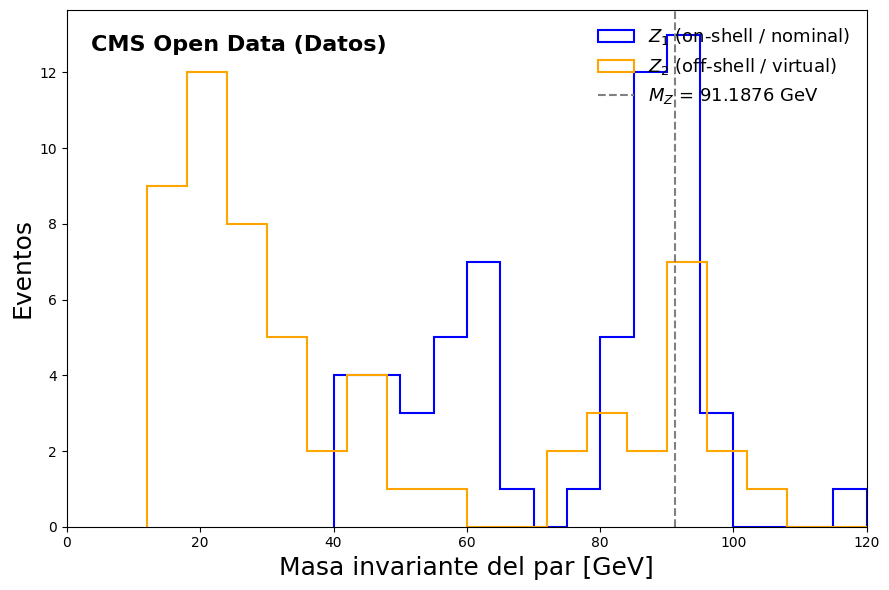

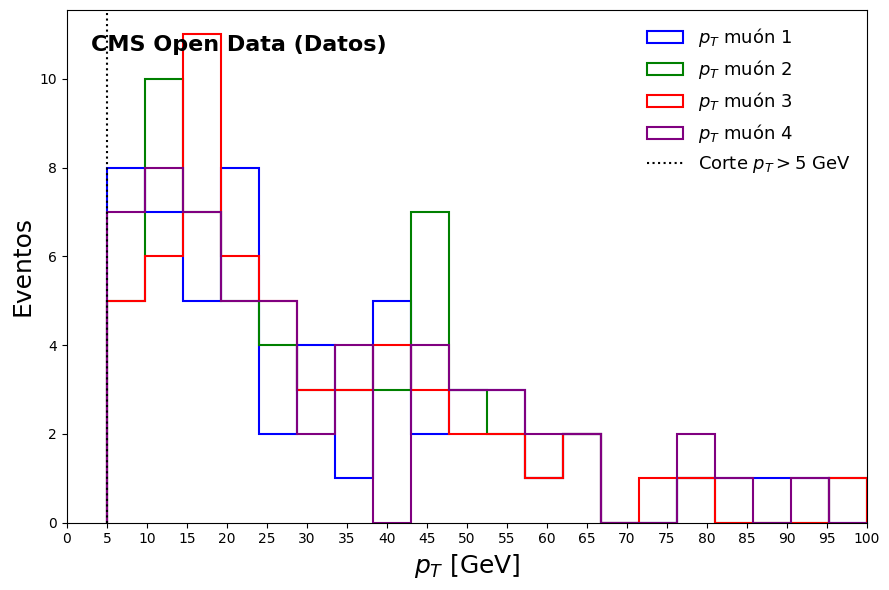

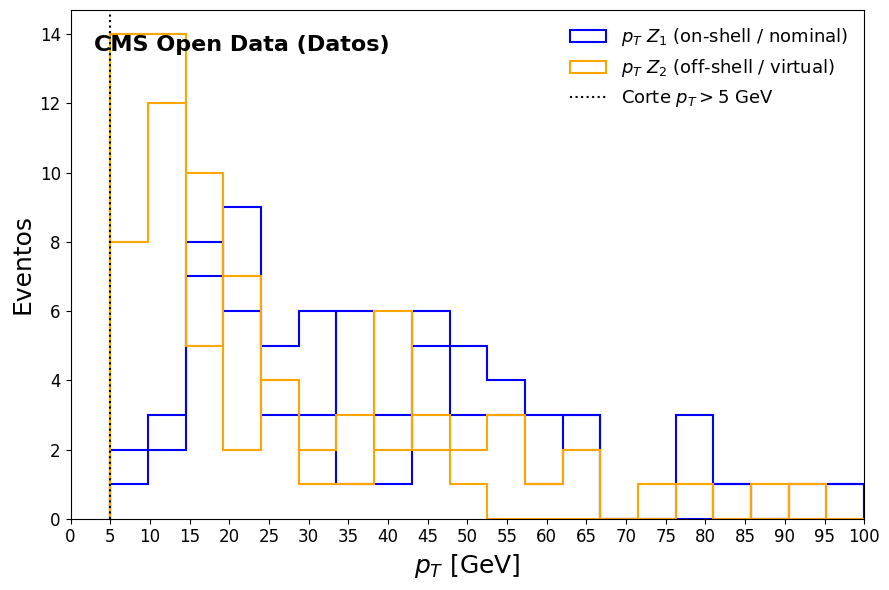

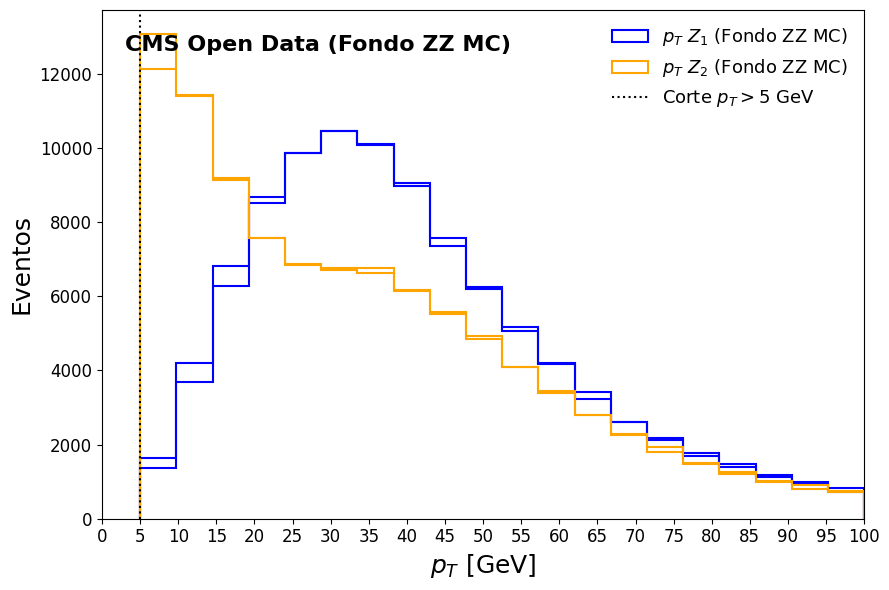

In [14]:
# 1. Gráfica: Masa invariante de los pares Z1 y Z2 (Datos)
fig, ax = plt.subplots(figsize=(9, 6))

ax.hist(
    df_final["mZ1"],
    bins=16,
    range=(40, 120),
    histtype="step",
    color="blue",
    linewidth=1.5,
    label="$Z_1$ (on-shell / nominal)",
)
ax.hist(
    df_final["mZ2"],
    bins=18,
    range=(12, 120),
    histtype="step",
    color="orange",
    linewidth=1.5,
    label="$Z_2$ (off-shell / virtual)",
)
ax.axvline(
    Z_Mass_Nominal,
    color="gray",
    linestyle="--",
    linewidth=1.5,
    label=f"$M_Z$ = {Z_Mass_Nominal} GeV",
)

ax.set_xlabel("Masa invariante del par [GeV]", fontsize=18)
ax.set_ylabel("Eventos", fontsize=18)
ax.set_xlim(0, 120)

ax.text(
    0.03,
    0.92,
    "CMS Open Data (Datos)",
    transform=ax.transAxes,
    fontsize=16,
    fontweight="bold",
)
ax.legend(loc="upper right", frameon=False, fontsize=13)
plt.tight_layout()
plt.show()

# 2. Gráfica: pT de los 4 muones individuales (Datos)
fig, ax = plt.subplots(figsize=(9, 6))
colores = ["blue", "green", "red", "purple"]
for i, color in zip(range(1, 5), colores):
    ax.hist(
        df_final[f"pt{i}"],
        bins=20,
        range=(5, 100),
        histtype="step",
        color=color,
        linewidth=1.5,
        label=f"$p_T$ muón {i}",
    )

ax.axvline(5, color="black", linestyle=":", linewidth=1.5, label="Corte $p_T > 5$ GeV")
ax.set_xlabel("$p_T$ [GeV]", fontsize=18)
ax.set_ylabel("Eventos", fontsize=18) 
ax.set_xlim(0, 100)
ax.set_xticks(range(0, 101, 5))
ax.text(
    0.03,
    0.92,
    "CMS Open Data (Datos)",
    transform=ax.transAxes,
    fontsize=16,
    fontweight="bold",
)
ax.legend(loc="upper right", frameon=False, fontsize=13)
plt.tight_layout()
plt.show()


# 3. Extraer el pT de los muones que forman Z1 y Z2 (Datos)
todos_indices = {1, 2, 3, 4}

pt_Z1_a = np.zeros(len(df_final))
pt_Z1_b = np.zeros(len(df_final))
for i in range(1, 5):
    mask_a = (df_final["Z1_idx_a"] == i)
    pt_Z1_a[mask_a] = df_final.loc[mask_a, f"pt{i}"]
    mask_b = (df_final["Z1_idx_b"] == i)
    pt_Z1_b[mask_b] = df_final.loc[mask_b, f"pt{i}"] 

df_final["pt_Z1a"] = pt_Z1_a
df_final["pt_Z1b"] = pt_Z1_b

pt_Z2_a = np.zeros(len(df_final))
pt_Z2_b = np.zeros(len(df_final))
idx_a_arr = df_final["Z1_idx_a"].astype(int).to_numpy()
idx_b_arr = df_final["Z1_idx_b"].astype(int).to_numpy()
pt_matrix = df_final[["pt1", "pt2", "pt3", "pt4"]].to_numpy()

for idx in range(len(df_final)):
    usados = {idx_a_arr[idx], idx_b_arr[idx]}
    restantes = sorted(todos_indices - usados)
    pt_Z2_a[idx] = pt_matrix[idx, restantes[0]-1]
    pt_Z2_b[idx] = pt_matrix[idx, restantes[1]-1]

df_final["pt_Z2a"] = pt_Z2_a
df_final["pt_Z2b"] = pt_Z2_b


# 4. Gráfica: pT de los muones de Z1 y Z2 (Datos)
fig, ax = plt.subplots(figsize=(9, 6))

ax.hist(
    df_final["pt_Z1a"], bins=20, range=(5, 100),
    histtype="step", color="blue", linewidth=1.5,
    label="$p_T$ $Z_1$ (on-shell / nominal)",
)
ax.hist(
    df_final["pt_Z1b"], bins=20, range=(5, 100),
    histtype="step", color="blue", linewidth=1.5,
)
ax.hist(
    df_final["pt_Z2a"], bins=20, range=(5, 100),
    histtype="step", color="orange", linewidth=1.5,
    label="$p_T$ $Z_2$ (off-shell / virtual)",
)
ax.hist(
    df_final["pt_Z2b"], bins=20, range=(5, 100),
    histtype="step", color="orange", linewidth=1.5,
)

ax.axvline(5, color="black", linestyle=":", linewidth=1.5, label="Corte $p_T > 5$ GeV")

ax.set_xlabel("$p_T$ [GeV]", fontsize=18)
ax.set_ylabel("Eventos", fontsize=18)
ax.set_xlim(0, 100)
ax.set_xticks(range(0, 101, 5))

ax.tick_params(axis='both', labelsize=12)
ax.text(
    0.03,
    0.92,
    "CMS Open Data (Datos)",
    transform=ax.transAxes,
    fontsize=16,
    fontweight="bold",
)
ax.legend(loc="upper right", frameon=False, fontsize=13)
plt.tight_layout()
plt.show()


# 5. Extraer el pT de los muones para el Fondo ZZ MC (df_final_zz)
pt_Z1_a_zz = np.zeros(len(df_final_zz))
pt_Z1_b_zz = np.zeros(len(df_final_zz))
for i in range(1, 5):
    mask_a = (df_final_zz["Z1_idx_a"] == i)
    pt_Z1_a_zz[mask_a] = df_final_zz.loc[mask_a, f"pt{i}"]
    mask_b = (df_final_zz["Z1_idx_b"] == i)
    pt_Z1_b_zz[mask_b] = df_final_zz.loc[mask_b, f"pt{i}"] 

df_final_zz["pt_Z1a"] = pt_Z1_a_zz
df_final_zz["pt_Z1b"] = pt_Z1_b_zz

pt_Z2_a_zz = np.zeros(len(df_final_zz))
pt_Z2_b_zz = np.zeros(len(df_final_zz))
idx_a_arr_zz = df_final_zz["Z1_idx_a"].astype(int).to_numpy()
idx_b_arr_zz = df_final_zz["Z1_idx_b"].astype(int).to_numpy()
pt_matrix_zz = df_final_zz[["pt1", "pt2", "pt3", "pt4"]].to_numpy()

for idx in range(len(df_final_zz)):
    usados = {idx_a_arr_zz[idx], idx_b_arr_zz[idx]}
    restantes = sorted(todos_indices - usados)
    pt_Z2_a_zz[idx] = pt_matrix_zz[idx, restantes[0]-1]
    pt_Z2_b_zz[idx] = pt_matrix_zz[idx, restantes[1]-1]

df_final_zz["pt_Z2a"] = pt_Z2_a_zz
df_final_zz["pt_Z2b"] = pt_Z2_b_zz


# 6. Gráfica: pT de los muones de Z1 y Z2 para el Fondo ZZ MC
fig, ax = plt.subplots(figsize=(9, 6))

ax.hist(
    df_final_zz["pt_Z1a"], bins=20, range=(5, 100),
    histtype="step", color="blue", linewidth=1.5,
    label="$p_T$ $Z_1$ (Fondo ZZ MC)",
)
ax.hist(
    df_final_zz["pt_Z1b"], bins=20, range=(5, 100),
    histtype="step", color="blue", linewidth=1.5,
)
ax.hist(
    df_final_zz["pt_Z2a"], bins=20, range=(5, 100),
    histtype="step", color="orange", linewidth=1.5,
    label="$p_T$ $Z_2$ (Fondo ZZ MC)",
)
ax.hist(
    df_final_zz["pt_Z2b"], bins=20, range=(5, 100),
    histtype="step", color="orange", linewidth=1.5,
)

ax.axvline(5, color="black", linestyle=":", linewidth=1.5, label="Corte $p_T > 5$ GeV")

ax.set_xlabel("$p_T$ [GeV]", fontsize=18)
ax.set_ylabel("Eventos", fontsize=18)
ax.set_xlim(0, 100)
ax.set_xticks(range(0, 101, 5))

ax.tick_params(axis='both', labelsize=12)
ax.text(
    0.03,
    0.92,
    "CMS Open Data (Fondo ZZ MC)",
    transform=ax.transAxes,
    fontsize=16,
    fontweight="bold",
)
ax.legend(loc="upper right", frameon=False, fontsize=13)
plt.tight_layout()
plt.show()

<>:112: SyntaxWarning: "\m" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\m"? A raw string is also an option.
<>:112: SyntaxWarning: "\m" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\m"? A raw string is also an option.
C:\Users\HP\AppData\Local\Temp\ipykernel_16176\2197961637.py:112: SyntaxWarning: "\m" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\m"? A raw string is also an option.
  label="$H \to ZZ^* \to 4\mu$ (mH = 125 GeV)", color="red", histtype='step', linewidth=2.5)


Datos reales filtrados: 59
Higgs filtrado:         12467
Fondo ZZ MC filtrado:   101807
Peso Higgs: 0.000097
Peso ZZ:    3.180094e-04


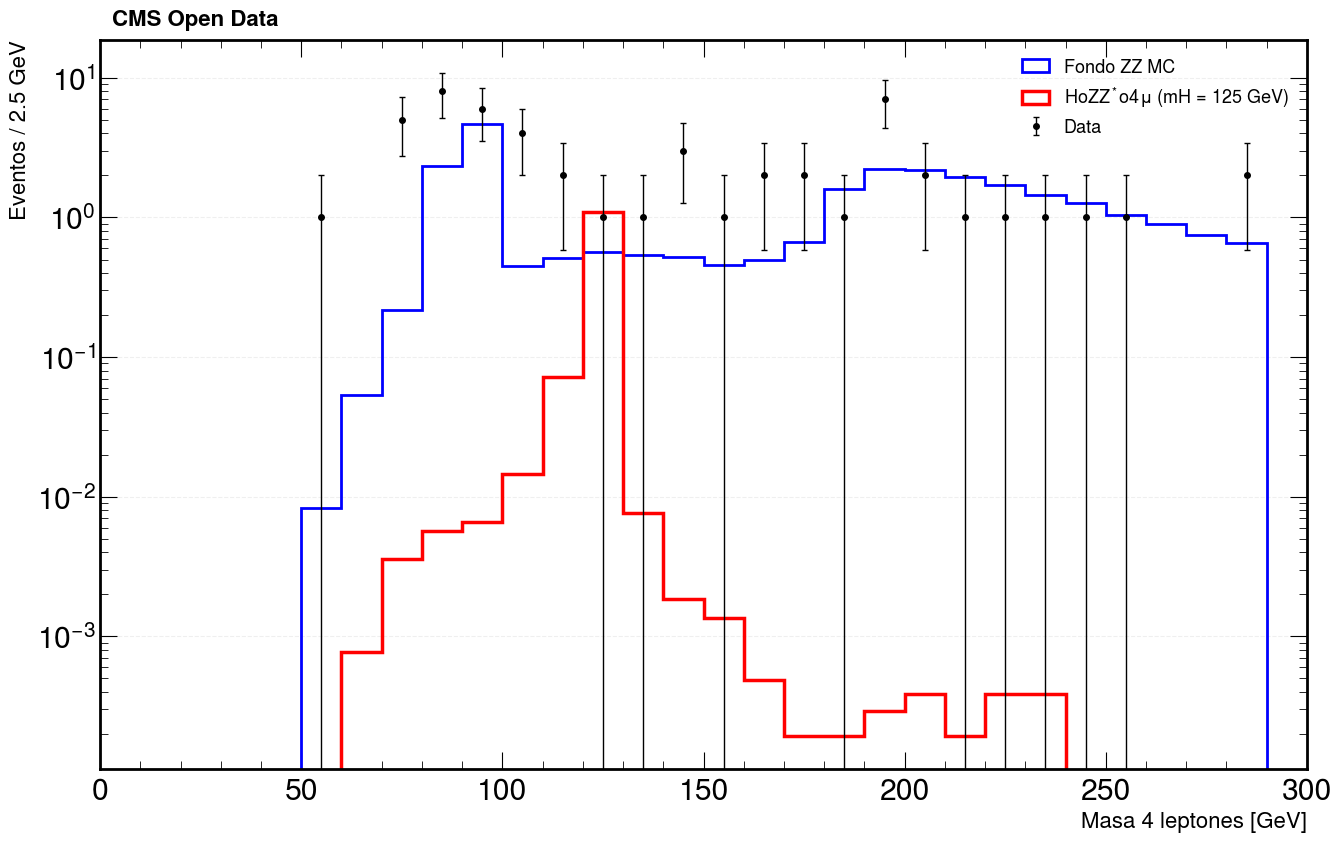

In [14]:
# Estilo CMS 
hep.style.use("CMS")

# Parámetros Físicos
m_mu = 0.10566  # Masa del muón [GeV/c²]

# Reconstrucción del 4-vector del sistema de 4 muones
def calcular_masa(df):
    px = 0; py = 0; pz = 0; E = 0
    for i in range(1, 5):
        pxi = df[f"pt{i}"] * np.cos(df[f"phi{i}"])
        pyi = df[f"pt{i}"] * np.sin(df[f"phi{i}"])
        pzi = df[f"pt{i}"] * np.sinh(df[f"eta{i}"])
        Ei  = np.sqrt(pxi**2 + pyi**2 + pzi**2 + m_mu**2)
        px += pxi; py += pyi; pz += pzi; E += Ei
        
    argumento_raiz = np.maximum(0, E**2 - (px**2 + py**2 + pz**2))
    return np.sqrt(argumento_raiz)

# Masa para Datos Reales
df_final["M"] = calcular_masa(df_final)
df_data_f = df_final

# Filtros y Masa para Higgs MC (df_4mu_higgs)
for i in range(1, 5):
    ip3d_h = np.sqrt(df_4mu_higgs[f"dxy{i}"] ** 2 + df_4mu_higgs[f"dz{i}"] ** 2)
    sig_h = np.sqrt(df_4mu_higgs[f"dxyErr{i}"] ** 2 + df_4mu_higgs[f"dzErr{i}"] ** 2)
    df_4mu_higgs[f"sip3d{i}"] = ip3d_h / sig_h

mask_pt_h  = (df_4mu_higgs["pt1"]>5)  & (df_4mu_higgs["pt2"]>5)  & (df_4mu_higgs["pt3"]>5)  & (df_4mu_higgs["pt4"]>5)
mask_eta_h = (df_4mu_higgs["eta1"].abs()<2.4) & (df_4mu_higgs["eta2"].abs()<2.4) & (df_4mu_higgs["eta3"].abs()<2.4) & (df_4mu_higgs["eta4"].abs()<2.4)
mask_iso_h = (df_4mu_higgs["iso1"]<0.40) & (df_4mu_higgs["iso2"]<0.40) & (df_4mu_higgs["iso3"]<0.40) & (df_4mu_higgs["iso4"]<0.40)
mask_sip_h = (df_4mu_higgs["sip3d1"]<4) & (df_4mu_higgs["sip3d2"]<4) & (df_4mu_higgs["sip3d3"]<4) & (df_4mu_higgs["sip3d4"]<4)

df_higgs_f = df_4mu_higgs[mask_pt_h & mask_eta_h & mask_iso_h & mask_sip_h].copy()

for (i, j) in pares_todos:
    df_higgs_f[f"dR_{i}{j}"] = delta_R(df_higgs_f, i, j)

mask_dR_h = True
for (i, j) in pares_todos:
    mask_dR_h = mask_dR_h & (df_higgs_f[f"dR_{i}{j}"] > 0.02)

df_higgs_f = df_higgs_f[mask_dR_h].copy()
df_higgs_f = identificar_Z_onoff(df_higgs_f)

df_higgs_f = df_higgs_f[
    (df_higgs_f["mZ1"] > 40) & (df_higgs_f["mZ1"] < 120) &
    (df_higgs_f["mZ2"] > 12) & (df_higgs_f["mZ2"] < 120)
].copy()

df_higgs_f["M"] = calcular_masa(df_higgs_f)


# Filtros y Masa para Fondo ZZ MC (df_final_zz)
for i in range(1, 5):
    ip3d_zz = np.sqrt(df_final_zz[f"dxy{i}"] ** 2 + df_final_zz[f"dz{i}"] ** 2)
    sig_zz = np.sqrt(df_final_zz[f"dxyErr{i}"] ** 2 + df_final_zz[f"dzErr{i}"] ** 2)
    df_final_zz[f"sip3d{i}"] = ip3d_zz / sig_zz

mask_pt_zz  = (df_final_zz["pt1"]>5)  & (df_final_zz["pt2"]>5)  & (df_final_zz["pt3"]>5)  & (df_final_zz["pt4"]>5)
mask_eta_zz = (df_final_zz["eta1"].abs()<2.4) & (df_final_zz["eta2"].abs()<2.4) & (df_final_zz["eta3"].abs()<2.4) & (df_final_zz["eta4"].abs()<2.4)
mask_iso_zz = (df_final_zz["iso1"]<0.40) & (df_final_zz["iso2"]<0.40) & (df_final_zz["iso3"]<0.40) & (df_final_zz["iso4"]<0.40)
mask_sip_zz = (df_final_zz["sip3d1"]<4) & (df_final_zz["sip3d2"]<4) & (df_final_zz["sip3d3"]<4) & (df_final_zz["sip3d4"]<4)

df_zz_f = df_final_zz[mask_pt_zz & mask_eta_zz & mask_iso_zz & mask_sip_zz].copy()

for (i, j) in pares_todos:
    df_zz_f[f"dR_{i}{j}"] = delta_R(df_zz_f, i, j)

mask_dR_zz = True
for (i, j) in pares_todos:
    mask_dR_zz = mask_dR_zz & (df_zz_f[f"dR_{i}{j}"] > 0.02)

df_zz_f = df_zz_f[mask_dR_zz].copy()
df_zz_f = identificar_Z_onoff(df_zz_f)

df_zz_f = df_zz_f[
    (df_zz_f["mZ1"] > 40) & (df_zz_f["mZ1"] < 120) &
    (df_zz_f["mZ2"] > 12) & (df_zz_f["mZ2"] < 120)
].copy()

df_zz_f["M"] = calcular_masa(df_zz_f)


print("Datos reales filtrados:", len(df_data_f))
print("Higgs filtrado:        ", len(df_higgs_f))
print("Fondo ZZ MC filtrado:  ", len(df_zz_f))

# Pesos oficiales del CERN
lumi    = 4.4669 * 1000
w_higgs = (0.0065 * lumi) / 299973.0
w_zz    = (0.077 * 1.386 * lumi) / 1499064.0

print(f"Peso Higgs: {w_higgs:.6f}")
print(f"Peso ZZ:    {w_zz:.6e}")


# Gráfico unificado con Datos, Higgs y Fondo ZZ MC 
mis_bins = np.arange(0, 300, 10)

plt.figure(figsize=(14, 9))

# 1. Fondo ZZ MC
plt.hist(df_zz_f["M"], bins=mis_bins,
         weights=np.full(len(df_zz_f), w_zz),
         label="Fondo ZZ MC", color="blue", histtype='step', linewidth=2)

# 2. Señal de Higgs
plt.hist(df_higgs_f["M"], bins=mis_bins,
         weights=np.full(len(df_higgs_f), w_higgs),
         label="$H \to ZZ^* \to 4\mu$ (mH = 125 GeV)", color="red", histtype='step', linewidth=2.5)

# 3. Datos Reales
counts, bin_edges = np.histogram(df_data_f["M"], bins=mis_bins)
bin_centers = (bin_edges[1:] + bin_edges[:-1]) / 2
plt.errorbar(bin_centers, counts, yerr=np.sqrt(counts),
             fmt='o', color='black', markersize=4,
             capsize=2, elinewidth=1, linestyle='none', label='Data')

# Estética de la gráfica
ax = plt.gca()
ax.text(0.01, 1.02, "CMS Open Data", transform=ax.transAxes,
        fontsize=16, fontweight='bold', fontstyle='normal', ha='left')
plt.xlabel("Masa 4 leptones [GeV]", fontsize=16)
plt.ylabel("Eventos / 2.5 GeV", fontsize=16)
plt.xlim(0, 300)
plt.yscale("log")

plt.legend(loc='upper right', frameon=False, fontsize=13)
plt.grid(axis='y', alpha=0.2, linestyle='--')
plt.tight_layout()
plt.show()

Datos reales filtrados: 59
Higgs filtrado:         12467
Fondo ZZ MC filtrado:   101807
Peso Higgs: 0.000097
Peso ZZ:    3.180094e-04


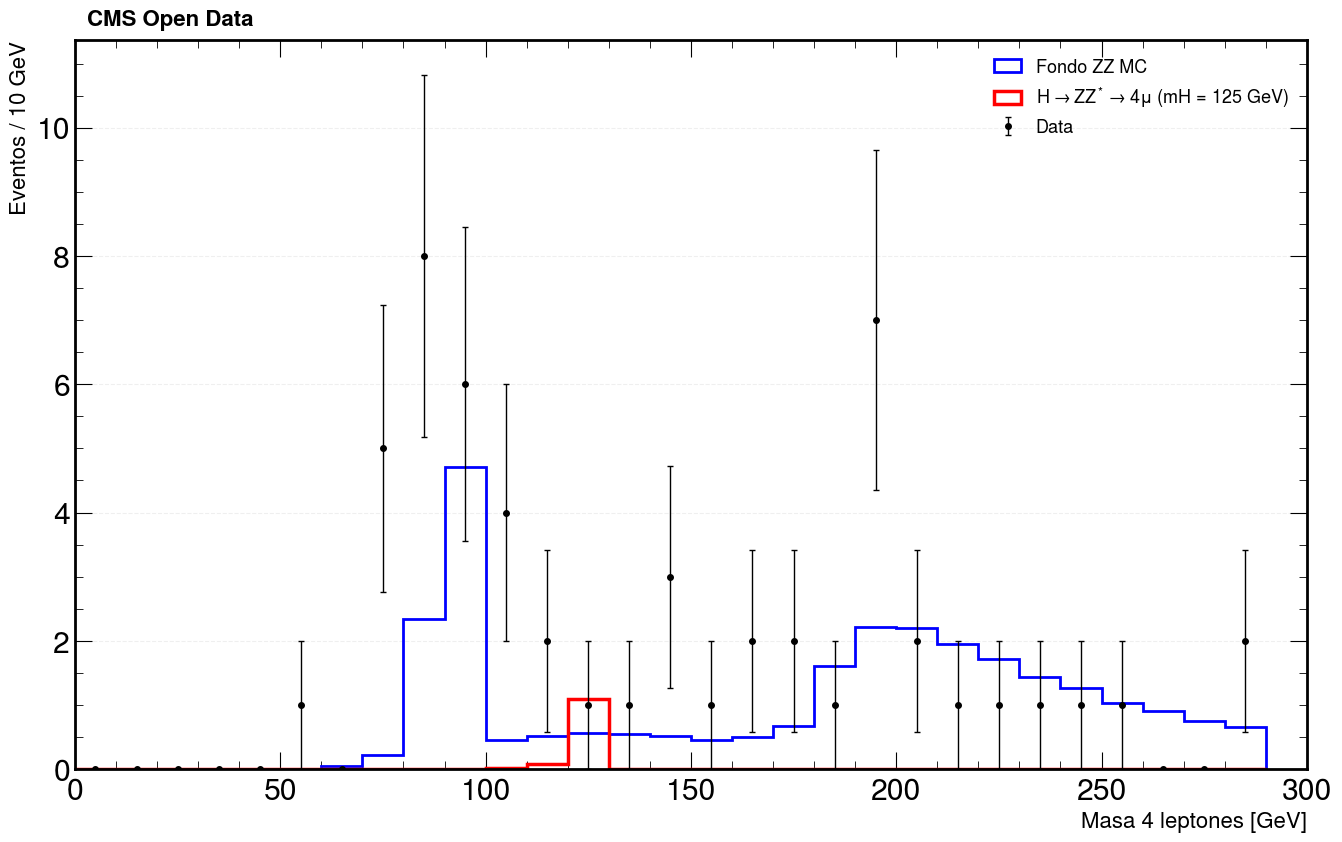

In [15]:
# Estilo CMS 
hep.style.use("CMS")

# Parámetros Físicos
m_mu = 0.10566  # Masa del muón [GeV/c²]

# Reconstrucción del 4-vector del sistema de 4 muones
def calcular_masa(df):
    px = 0; py = 0; pz = 0; E = 0
    for i in range(1, 5):
        pxi = df[f"pt{i}"] * np.cos(df[f"phi{i}"])
        pyi = df[f"pt{i}"] * np.sin(df[f"phi{i}"])
        pzi = df[f"pt{i}"] * np.sinh(df[f"eta{i}"])
        Ei  = np.sqrt(pxi**2 + pyi**2 + pzi**2 + m_mu**2)
        px += pxi; py += pyi; pz += pzi; E += Ei
        
    argumento_raiz = np.maximum(0, E**2 - (px**2 + py**2 + pz**2))
    return np.sqrt(argumento_raiz)

# Masa para Datos Reales
df_final["M"] = calcular_masa(df_final)
df_data_f = df_final

# Filtros y Masa para Higgs MC (df_4mu_higgs)
for i in range(1, 5):
    ip3d_h = np.sqrt(df_4mu_higgs[f"dxy{i}"] ** 2 + df_4mu_higgs[f"dz{i}"] ** 2)
    sig_h = np.sqrt(df_4mu_higgs[f"dxyErr{i}"] ** 2 + df_4mu_higgs[f"dzErr{i}"] ** 2)
    df_4mu_higgs[f"sip3d{i}"] = ip3d_h / sig_h

mask_pt_h  = (df_4mu_higgs["pt1"]>5)  & (df_4mu_higgs["pt2"]>5)  & (df_4mu_higgs["pt3"]>5)  & (df_4mu_higgs["pt4"]>5)
mask_eta_h = (df_4mu_higgs["eta1"].abs()<2.4) & (df_4mu_higgs["eta2"].abs()<2.4) & (df_4mu_higgs["eta3"].abs()<2.4) & (df_4mu_higgs["eta4"].abs()<2.4)
mask_iso_h = (df_4mu_higgs["iso1"]<0.40) & (df_4mu_higgs["iso2"]<0.40) & (df_4mu_higgs["iso3"]<0.40) & (df_4mu_higgs["iso4"]<0.40)
mask_sip_h = (df_4mu_higgs["sip3d1"]<4) & (df_4mu_higgs["sip3d2"]<4) & (df_4mu_higgs["sip3d3"]<4) & (df_4mu_higgs["sip3d4"]<4)

df_higgs_f = df_4mu_higgs[mask_pt_h & mask_eta_h & mask_iso_h & mask_sip_h].copy()

for (i, j) in pares_todos:
    df_higgs_f[f"dR_{i}{j}"] = delta_R(df_higgs_f, i, j)

mask_dR_h = True
for (i, j) in pares_todos:
    mask_dR_h = mask_dR_h & (df_higgs_f[f"dR_{i}{j}"] > 0.02)

df_higgs_f = df_higgs_f[mask_dR_h].copy()
df_higgs_f = identificar_Z_onoff(df_higgs_f)

df_higgs_f = df_higgs_f[
    (df_higgs_f["mZ1"] > 40) & (df_higgs_f["mZ1"] < 120) &
    (df_higgs_f["mZ2"] > 12) & (df_higgs_f["mZ2"] < 120)
].copy()

df_higgs_f["M"] = calcular_masa(df_higgs_f)


# Filtros y Masa para Fondo ZZ MC (df_final_zz)
for i in range(1, 5):
    ip3d_zz = np.sqrt(df_final_zz[f"dxy{i}"] ** 2 + df_final_zz[f"dz{i}"] ** 2)
    sig_zz = np.sqrt(df_final_zz[f"dxyErr{i}"] ** 2 + df_final_zz[f"dzErr{i}"] ** 2)
    df_final_zz[f"sip3d{i}"] = ip3d_zz / sig_zz

mask_pt_zz  = (df_final_zz["pt1"]>5)  & (df_final_zz["pt2"]>5)  & (df_final_zz["pt3"]>5)  & (df_final_zz["pt4"]>5)
mask_eta_zz = (df_final_zz["eta1"].abs()<2.4) & (df_final_zz["eta2"].abs()<2.4) & (df_final_zz["eta3"].abs()<2.4) & (df_final_zz["eta4"].abs()<2.4)
mask_iso_zz = (df_final_zz["iso1"]<0.40) & (df_final_zz["iso2"]<0.40) & (df_final_zz["iso3"]<0.40) & (df_final_zz["iso4"]<0.40)
mask_sip_zz = (df_final_zz["sip3d1"]<4) & (df_final_zz["sip3d2"]<4) & (df_final_zz["sip3d3"]<4) & (df_final_zz["sip3d4"]<4)

df_zz_f = df_final_zz[mask_pt_zz & mask_eta_zz & mask_iso_zz & mask_sip_zz].copy()

for (i, j) in pares_todos:
    df_zz_f[f"dR_{i}{j}"] = delta_R(df_zz_f, i, j)

mask_dR_zz = True
for (i, j) in pares_todos:
    mask_dR_zz = mask_dR_zz & (df_zz_f[f"dR_{i}{j}"] > 0.02)

df_zz_f = df_zz_f[mask_dR_zz].copy()
df_zz_f = identificar_Z_onoff(df_zz_f)

df_zz_f = df_zz_f[
    (df_zz_f["mZ1"] > 40) & (df_zz_f["mZ1"] < 120) &
    (df_zz_f["mZ2"] > 12) & (df_zz_f["mZ2"] < 120)
].copy()

df_zz_f["M"] = calcular_masa(df_zz_f)


print("Datos reales filtrados:", len(df_data_f))
print("Higgs filtrado:        ", len(df_higgs_f))
print("Fondo ZZ MC filtrado:  ", len(df_zz_f))

# Pesos oficiales del CERN
lumi    = 4.4669 * 1000
w_higgs = (0.0065 * lumi) / 299973.0
w_zz    = (0.077 * 1.386 * lumi) / 1499064.0

print(f"Peso Higgs: {w_higgs:.6f}")
print(f"Peso ZZ:    {w_zz:.6e}")


# Gráfico unificado con Datos, Higgs y Fondo ZZ MC (Escala Lineal)
mis_bins = np.arange(0, 300, 10)

plt.figure(figsize=(14, 9))

# 1. Fondo ZZ MC
plt.hist(df_zz_f["M"], bins=mis_bins,
         weights=np.full(len(df_zz_f), w_zz),
         label="Fondo ZZ MC", color="blue", histtype='step', linewidth=2)

# 2. Señal de Higgs
plt.hist(df_higgs_f["M"], bins=mis_bins,
         weights=np.full(len(df_higgs_f), w_higgs),
         label=r"$H \to ZZ^* \to 4\mu$ (mH = 125 GeV)", color="red", histtype='step', linewidth=2.5)

# 3. Datos Reales
counts, bin_edges = np.histogram(df_data_f["M"], bins=mis_bins)
bin_centers = (bin_edges[1:] + bin_edges[:-1]) / 2
plt.errorbar(bin_centers, counts, yerr=np.sqrt(counts),
             fmt='o', color='black', markersize=4,
             capsize=2, elinewidth=1, linestyle='none', label='Data')

# Estética de la gráfica
ax = plt.gca()
ax.text(0.01, 1.02, "CMS Open Data", transform=ax.transAxes,
        fontsize=16, fontweight='bold', fontstyle='normal', ha='left')
plt.xlabel("Masa 4 leptones [GeV]", fontsize=16)
plt.ylabel("Eventos / 10 GeV", fontsize=16)
plt.xlim(0, 300)
plt.yscale("linear")  # <--- Cambiado a escala lineal

plt.legend(loc='upper right', frameon=False, fontsize=13)
plt.grid(axis='y', alpha=0.2, linestyle='--')
plt.tight_layout()
plt.show()